In [4]:
pip install seaborn


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("TensorFlow:", tf.__version__)
print("All libraries imported successfully!")

Python: c:\Users\bhara\OneDrive\Desktop\fire vs no fire\venv\Scripts\python.exe
NumPy: 2.5.4
Pandas: 3.1.1
TensorFlow: 2.22.0-rc0
All libraries imported successfully!


In [6]:

# Step 2: Check the files and folders in our project

from pathlib import Path

# Get the current project directory
PROJECT_DIR = Path.cwd()

print("Project folder:", PROJECT_DIR)
print("\nFiles and folders available:")

# Display all files and folders in alphabetical order
for item in sorted(PROJECT_DIR.iterdir()):
    print(item.name)


Project folder: c:\Users\bhara\OneDrive\Desktop\fire vs no fire

Files and folders available:
Data
venv


In [8]:

# Step 3: Explore the dataset folder

# Set the dataset directory path
DATASET_DIR = PROJECT_DIR / "data"

print("Dataset path:", DATASET_DIR)
print("\nDataset folder contents:")

# Display files and folders inside the dataset directory
for item in sorted(DATASET_DIR.iterdir()):
    if item.is_dir():
        print(f"[Folder] {item.name}")
    else:
        print(f"[File] {item.name}")


Dataset path: c:\Users\bhara\OneDrive\Desktop\fire vs no fire\data

Dataset folder contents:
[Folder] Test_Data
[Folder] Train_Data


In [9]:

# Step 4: Explore the train and test folders

# Check the contents of both folders
for folder_name in ["Test_Data", "Train_Data"]:
    folder_path = DATASET_DIR / folder_name

    print(f"\nContents of {folder_name} folder:")

    # Display the class folders or files inside each folder
    for item in sorted(folder_path.iterdir()):
        if item.is_dir():
            print(f"  [Folder] {item.name}")
        else:
            print(f"  [File] {item.name}")




Contents of Test_Data folder:
  [Folder] Fire
  [Folder] Non_Fire

Contents of Train_Data folder:
  [Folder] Fire
  [Folder] Non_Fire


In [10]:
# Step 5: Count images in each class of the train and test datasets

# Check both training and testing datasets
for split in ["Test_Data", "Train_Data"]:
    split_dir = DATASET_DIR / split

    print(f"\n{split.upper()} dataset:")

    # Check each class folder
    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():

            # Find all supported image files, including those in subfolders
            images = [
                file for file in class_dir.rglob("*")
                if file.is_file()
                and file.suffix.lower() in [".jpg", ".jpeg", ".png"]
            ]

            # Display the number of images in this class
            print(f"{class_dir.name}: {len(images)} images")



TEST_DATA dataset:
Fire: 25 images
Non_Fire: 25 images

TRAIN_DATA dataset:
Fire: 2500 images
Non_Fire: 2500 images


In [14]:

# Step 6: Check dataset image counts and image dimensions

from PIL import Image

# Define the train and test directories
BASE_PATH = DATASET_DIR
TRAIN_DIR = BASE_PATH / "Train_Data"
TEST_DIR = BASE_PATH / "Test_Data"

# Supported image file formats
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def get_image_details(folder_path):
    print(f"\n--- {folder_path.name.upper()} DATA DETAILS ---")

    # Check whether the folder exists
    if not folder_path.exists():
        print(f"Folder not found: {folder_path}")
        return

    total_images = 0

    # Check each class folder
    for class_folder in sorted(folder_path.iterdir()):
        if not class_folder.is_dir():
            continue

        # Find images directly inside the class folder
        images = [
            file for file in class_folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in VALID_EXTENSIONS
        ]

        count = len(images)
        total_images += count

        print(f"Class '{class_folder.name}': {count} images")

        # Inspect one sample image to check its dimensions and color mode
        if count > 0:
            try:
                with Image.open(images[0]) as img:
                    width, height = img.size
                    channels = len(img.getbands())

                    print(
                        f"  Sample image: Height={height}, "
                        f"Width={width}, Channels={channels}, "
                        f"Mode={img.mode}"
                    )
            except Exception as error:
                print(f"  Could not open sample image: {error}")

    print(f"Total images in {folder_path.name}: {total_images}")


# Check both datasets
get_image_details(TRAIN_DIR)
get_image_details(TEST_DIR)



--- TRAIN_DATA DATA DETAILS ---
Class 'Fire': 2500 images
  Sample image: Height=250, Width=250, Channels=3, Mode=RGB
Class 'Non_Fire': 2500 images
  Sample image: Height=250, Width=250, Channels=3, Mode=RGB
Total images in Train_Data: 5000

--- TEST_DATA DATA DETAILS ---
Class 'Fire': 25 images
  Sample image: Height=749, Width=1200, Channels=3, Mode=RGB
Class 'Non_Fire': 25 images
  Sample image: Height=600, Width=800, Channels=3, Mode=RGB
Total images in Test_Data: 50


In [ ]:
# Step 7: Create a DataFrame containing image metadata

data = []

# Supported image file formats
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Scan both training and testing folders
for split in ["Train_Data", "Test_Data"]:
    split_dir = DATASET_DIR / split

    if not split_dir.exists():
        print(f"Warning: Folder not found: {split_dir}")
        continue

    # Visit each class folder
    for class_folder in sorted(split_dir.iterdir()):
        if not class_folder.is_dir():
            continue

        # Collect images from the current class folder
        for img_path in sorted(class_folder.iterdir()):
            if not img_path.is_file():
                continue

            if img_path.suffix.lower() not in VALID_EXTENSIONS:
                continue

            # Read the image dimensions
            try:
                with Image.open(img_path) as img:
                    width, height = img.size
            except Exception:
                width, height = None, None

            # Store information about this image
            data.append({
                "filepath": str(img_path),
                "filename": img_path.name,
                "label": class_folder.name,
                "split": split,
                "width": width,
                "height": height
            })

# Convert the collected metadata into a DataFrame
df = pd.DataFrame(
    data,
    columns=[
        "filepath", "filename", "label",
        "split", "width", "height"
    ]
)

# Display dataset summary
print(f"Total images: {len(df)}")
print(f"Total columns: {len(df.columns)}")

print("\nImages in each split:")
print(df["split"].value_counts())

print("\nClass distribution in each split:")
print(df.groupby(["split", "label"]).size())

# Display the first five rows
display(df.head())

Total images: 5050
Total columns: 6

Images in each split:
split
Train_Data    5000
Test_Data       50
Name: count, dtype: int64

Class distribution in each split:
split       label   
Test_Data   Fire          25
            Non_Fire      25
Train_Data  Fire        2500
            Non_Fire    2500
dtype: int64


,filepath,filename,label,split,width,height
0,c:\Users\bhara\OneDrive\Desktop\fire vs no fir...,F_0.jpg,Fire,Train_Data,250.0,250.0
1,c:\Users\bhara\OneDrive\Desktop\fire vs no fir...,F_1.jpg,Fire,Train_Data,250.0,250.0
2,c:\Users\bhara\OneDrive\Desktop\fire vs no fir...,F_10.jpg,Fire,Train_Data,250.0,250.0
3,c:\Users\bhara\OneDrive\Desktop\fire vs no fir...,F_100.jpg,Fire,Train_Data,250.0,250.0
4,c:\Users\bhara\OneDrive\Desktop\fire vs no fir...,F_1000.jpg,Fire,Train_Data,194.0,260.0


In [17]:
df.shape

(5050, 6)

In [18]:
df.isna().sum()

filepath      0
filename      0
label         0
split         0
width       389
height      389
dtype: int64

Image count by class:
label
Fire        2525
Non_Fire    2525
Name: count, dtype: int64


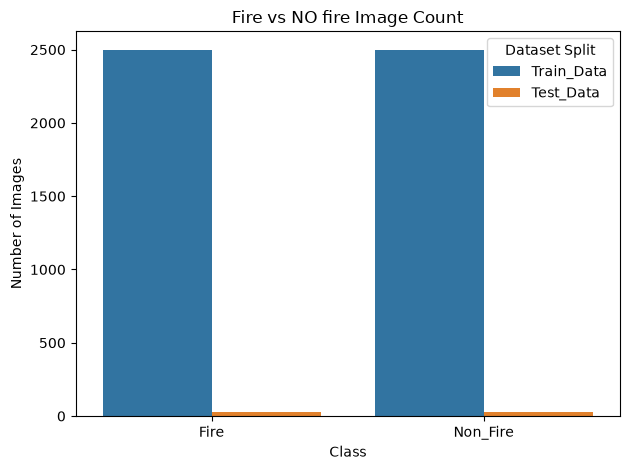

In [19]:

# Step 8: Analyze and visualize class distribution

# Count images in each class
print("Image count by class:")
print(df["label"].value_counts())

# Visualize class distribution separately for train and test
sns.countplot(data=df, x="label", hue="split")

plt.title("Fire vs NO fire Image Count")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()


In [20]:
print(df.columns.tolist())
print(df.head(3))

['filepath', 'filename', 'label', 'split', 'width', 'height']
                                            filepath  filename label  \
0  c:\Users\bhara\OneDrive\Desktop\fire vs no fir...   F_0.jpg  Fire   
1  c:\Users\bhara\OneDrive\Desktop\fire vs no fir...   F_1.jpg  Fire   
2  c:\Users\bhara\OneDrive\Desktop\fire vs no fir...  F_10.jpg  Fire   

        split  width  height  
0  Train_Data  250.0   250.0  
1  Train_Data  250.0   250.0  
2  Train_Data  250.0   250.0  


In [22]:
# Step 9: Split the dataset into training and testing sets

# Separate image paths and class labels
X = df["filepath"]
y = df["label"]

# Split the data into 80% training and 20% testing
# Stratification preserves the class proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Total images:", len(df))
print("Training images:", len(X_train))
print("Testing images:", len(X_test))

# Display class distribution in the training set
print("\nTraining class distribution:")
print(y_train.value_counts())

# Display class distribution in the testing set
print("\nTesting class distribution:")
print(y_test.value_counts())

Total images: 5050
Training images: 4040
Testing images: 1010

Training class distribution:
label
Fire        2020
Non_Fire    2020
Name: count, dtype: int64

Testing class distribution:
label
Non_Fire    505
Fire        505
Name: count, dtype: int64


In [23]:

# Step 10: Check the shapes of training and testing data

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (4040,)
X_test shape: (1010,)
y_train shape: (4040,)
y_test shape: (1010,)


Image shape (height, width, channels): (1080, 1920, 3)
Minimum pixel value: 0
Maximum pixel value: 255
Normalized minimum: 0.0
Normalized maximum: 1.0


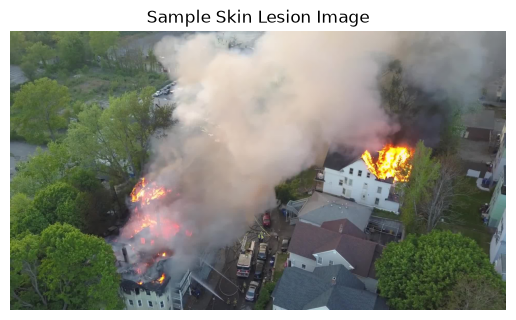

In [24]:
# Step 11: Load, inspect, normalize, and display a sample image

# Get the file path of one training image
sample_path = X_train.iloc[0]

# Open the image and convert it to RGB format
with Image.open(sample_path) as img:
    sample_image = img.convert("RGB")

# Convert the image into a NumPy array
sample_array = np.array(sample_image)

# Check the image shape and original pixel range
print("Image shape (height, width, channels):", sample_array.shape)
print("Minimum pixel value:", sample_array.min())
print("Maximum pixel value:", sample_array.max())

# Normalize pixel values from 0–255 to 0–1
sample_normalized = sample_array.astype("float32") / 255.0

print("Normalized minimum:", sample_normalized.min())
print("Normalized maximum:", sample_normalized.max())

# Display the normalized image
plt.imshow(sample_normalized)
plt.title("Sample Skin Lesion Image")
plt.axis("off")
plt.show()

In [25]:
df.isna().sum()

filepath      0
filename      0
label         0
split         0
width       389
height      389
dtype: int64

In [ ]:
# Step 12: Load and preprocess images for the CNN model

# Define image size and batch size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Assign numeric labels consistently
# non fire  = 0, fire = 1
class_to_number = {
    "Non_Fire": 0,
    "Fire": 1
}

# Convert text labels into numeric labels
y_train_num = y_train.map(class_to_number).to_numpy()
y_test_num = y_test.map(class_to_number).to_numpy()

# Check that all labels were converted successfully
assert not pd.isna(y_train_num).any(), "Unknown label found in y_train"
assert not pd.isna(y_test_num).any(), "Unknown label found in y_test"


# Function to load and preprocess one image
def load_image(image_path, label):
    # Read the image file
    image = tf.io.read_file(image_path)

    # Decode the image and convert it to RGB
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Define the image shape for TensorFlow
    image.set_shape([None, None, 3])

    # Resize the image to 224 × 224 pixels
    image = tf.image.resize(image, IMG_SIZE)

    # Scale pixel values from 0–255 to 0–1
    image = image / 255.0

    return image, label


# Create the training dataset
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train.to_numpy(), y_train_num)
)

train_ds = (
    train_ds
    .shuffle(buffer_size=1000, seed=42)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Create the testing dataset
test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test.to_numpy(), y_test_num)
)

test_ds = (
    test_ds
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Display dataset information
print("Class mapping:", class_to_number)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Class mapping: {'Non_Fire': 0, 'Fire': 1}
Training batches: 127
Testing batches: 32


In [27]:

# Deep learning libraries
from tensorflow import keras
from tensorflow.keras import layers

# Step 13: Build a CNN model from scratch for binary classification
model = keras.Sequential([

    # Input: RGB images of size 224 × 224
    keras.Input(shape=(224, 224, 3)),

    # Convolution block 1: learn basic features such as edges and textures
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2: learn more detailed image patterns
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3: learn higher-level visual features
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Summarize each feature map into a single value
    layers.GlobalAveragePooling2D(),

    # Reduce overfitting by randomly dropping units during training
    layers.Dropout(0.3),

    # Output one probability for the Malignant class
    layers.Dense(1, activation="sigmoid")
])

# Display the model architecture and parameter counts
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,377 (364.75 KB)

 Trainable params: 93,377 (364.75 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:

# Compile the CNN model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("CNN model compiled successfully! ✅")


CNN model compiled successfully! ✅


In [ ]:
# Step 15: Compile the CNN model

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("CNN model compiled successfully!")

In [31]:
# Model training with Early Stopping (taaki jab model improve hona band ho jaye, training wahin ruk jaye)
epochs = 15

history = model.fit(
    train_ds,
    epochs=epochs,
    validation_data=test_ds,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_loss', 
            patience=3, 
            restore_best_weights=True
        )
    ]
)

print("Model training completed successfully! 🔥")

Epoch 1/15


c:\Users\bhara\OneDrive\Desktop\fire vs no fire\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


InvalidArgumentError: {{function_node __wrapped__IteratorGetNextAsOptional_device_/job:localhost/replica:0/task:0/device:CPU:0}} Input is empty.
	 [[{{node decode_image/DecodeImage}}]] [Op:IteratorGetNextAsOptional] name: 

In [34]:
# Epochs define karein (shuru mein 10-15 epochs thik rehte hain)
EPOCHS = 15

# Model Training
history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=test_ds
)

print("Model training complete! 🎉")

Epoch 1/15


c:\Users\bhara\OneDrive\Desktop\fire vs no fire\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


InvalidArgumentError: {{function_node __wrapped__IteratorGetNextAsOptional_device_/job:localhost/replica:0/task:0/device:CPU:0}} Input is empty.
	 [[{{node decode_image/DecodeImage}}]] [Op:IteratorGetNextAsOptional] name: 

In [35]:
# Error ka poora message dekhne ke liye try-except block chalayein
try:
    model.fit(train_ds, epochs=1, validation_data=test_ds)
except Exception as e:
    import traceback
    traceback.print_exc()

  1/127 ━━━━━━━━━━━━━━━━━━━━ 6:38 3s/step - accuracy: 0.6875 - loss: 0.6721 - precision: 0.0000e+00 - recall: 0.0000e+00

Traceback (most recent call last):
  File "C:\Users\bhara\AppData\Local\Temp\ipykernel_11084\3988791702.py", line 3, in <module>
    model.fit(train_ds, epochs=1, validation_data=test_ds)
    ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\bhara\OneDrive\Desktop\fire vs no fire\venv\Lib\site-packages\keras\src\utils\traceback_utils.py", line 123, in error_handler
    raise e.with_traceback(filtered_tb) from None
  File "c:\Users\bhara\OneDrive\Desktop\fire vs no fire\venv\Lib\site-packages\tensorflow\python\framework\ops.py", line 6084, in raise_from_not_ok_status
    raise core._status_to_exception(e) from None  # pylint: disable=protected-access
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
tensorflow.python.framework.errors_impl.InvalidArgumentError: {{function_node __wrapped__IteratorGetNextAsOptional_device_/job:localhost/replica:0/task:0/device:CPU:0}} Input is empty.
	 [[{{node decode_image/DecodeImage}}]] [Op:IteratorGetNextAsOptional] name: 


In [36]:
import os
from PIL import Image
import pandas as pd

def clean_dataset(X, y):
    valid_X = []
    valid_y = []
    for path, label in zip(X, y):
        if os.path.exists(path) and os.path.getsize(path) > 0:
            try:
                with Image.open(path) as img:
                    img.verify() # Check karein ki image theek hai ya nahi
                valid_X.append(path)
                valid_y.append(label)
            except Exception:
                print(f"Corrupt image skipped: {path}")
        else:
            print(f"Empty or missing file skipped: {path}")
    return pd.Series(valid_X), pd.Series(valid_y)

# Train aur Test dono ko clean karein
X_train, y_train = clean_dataset(X_train, y_train)
X_test, y_test = clean_dataset(X_test, y_test)

print("\nCleaning Complete! ✅")
print("New Training images count:", len(X_train))
print("New Testing images count:", len(X_test))

Empty or missing file skipped: c:\Users\bhara\OneDrive\Desktop\fire vs no fire\data\Train_Data\Fire\F_752.jpg
Empty or missing file skipped: c:\Users\bhara\OneDrive\Desktop\fire vs no fire\data\Train_Data\Fire\F_691.jpg
Empty or missing file skipped: c:\Users\bhara\OneDrive\Desktop\fire vs no fire\data\Train_Data\Fire\F_806.jpg
Empty or missing file skipped: c:\Users\bhara\OneDrive\Desktop\fire vs no fire\data\Train_Data\Fire\F_705.jpg
Empty or missing file skipped: c:\Users\bhara\OneDrive\Desktop\fire vs no fire\data\Train_Data\Fire\F_902.jpg
Empty or missing file skipped: c:\Users\bhara\OneDrive\Desktop\fire vs no fire\data\Train_Data\Fire\F_788.jpg
Empty or missing file skipped: c:\Users\bhara\OneDrive\Desktop\fire vs no fire\data\Train_Data\Fire\F_750.jpg
Empty or missing file skipped: c:\Users\bhara\OneDrive\Desktop\fire vs no fire\data\Train_Data\Fire\F_610.jpg
Empty or missing file skipped: c:\Users\bhara\OneDrive\Desktop\fire vs no fire\data\Train_Data\Fire\F_688.jpg
Empty or m

In [37]:
# Step 12: Load and preprocess images for the CNN model

# Define image size and batch size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Assign numeric labels consistently
# non fire  = 0, fire = 1
class_to_number = {
    "Non_Fire": 0,
    "Fire": 1
}

# Convert text labels into numeric labels
y_train_num = y_train.map(class_to_number).to_numpy()
y_test_num = y_test.map(class_to_number).to_numpy()

# Check that all labels were converted successfully
assert not pd.isna(y_train_num).any(), "Unknown label found in y_train"
assert not pd.isna(y_test_num).any(), "Unknown label found in y_test"


# Function to load and preprocess one image
def load_image(image_path, label):
    # Read the image file
    image = tf.io.read_file(image_path)

    # Decode the image and convert it to RGB
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Define the image shape for TensorFlow
    image.set_shape([None, None, 3])

    # Resize the image to 224 × 224 pixels
    image = tf.image.resize(image, IMG_SIZE)

    # Scale pixel values from 0–255 to 0–1
    image = image / 255.0

    return image, label


# Create the training dataset
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train.to_numpy(), y_train_num)
)

train_ds = (
    train_ds
    .shuffle(buffer_size=1000, seed=42)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Create the testing dataset
test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test.to_numpy(), y_test_num)
)

test_ds = (
    test_ds
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Display dataset information
print("Class mapping:", class_to_number)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Class mapping: {'Non_Fire': 0, 'Fire': 1}
Training batches: 117
Testing batches: 29


In [38]:

# Deep learning libraries
from tensorflow import keras
from tensorflow.keras import layers

# Step 13: Build a CNN model from scratch for binary classification
model = keras.Sequential([

    # Input: RGB images of size 224 × 224
    keras.Input(shape=(224, 224, 3)),

    # Convolution block 1: learn basic features such as edges and textures
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2: learn more detailed image patterns
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3: learn higher-level visual features
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Summarize each feature map into a single value
    layers.GlobalAveragePooling2D(),

    # Reduce overfitting by randomly dropping units during training
    layers.Dropout(0.3),

    # Output one probability for the Malignant class
    layers.Dense(1, activation="sigmoid")
])

# Display the model architecture and parameter counts
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,377 (364.75 KB)

 Trainable params: 93,377 (364.75 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:

# Compile the CNN model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("CNN model compiled successfully! ✅")


CNN model compiled successfully! ✅


In [41]:
# Model training with Early Stopping (taaki jab model improve hona band ho jaye, training wahin ruk jaye)
epochs = 15

history = model.fit(
    train_ds,
    epochs=epochs,
    validation_data=test_ds,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_loss', 
            patience=3, 
            restore_best_weights=True
        )
    ]
)

print("Model training completed successfully! 🔥")

Epoch 1/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 107s 902ms/step - accuracy: 0.8566 - loss: 0.3351 - precision: 0.8956 - recall: 0.7788 - val_accuracy: 0.8927 - val_loss: 0.3199 - val_precision: 0.8430 - val_recall: 0.9378
Epoch 2/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 90s 766ms/step - accuracy: 0.8981 - loss: 0.2637 - precision: 0.9266 - recall: 0.8452 - val_accuracy: 0.9112 - val_loss: 0.2553 - val_precision: 0.8944 - val_recall: 0.9115
Epoch 3/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 88s 753ms/step - accuracy: 0.9077 - loss: 0.2389 - precision: 0.9309 - recall: 0.8632 - val_accuracy: 0.9112 - val_loss: 0.2390 - val_precision: 0.9179 - val_recall: 0.8828
Epoch 4/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 101s 864ms/step - accuracy: 0.9109 - loss: 0.2315 - precision: 0.9342 - recall: 0.8673 - val_accuracy: 0.9187 - val_loss: 0.2517 - val_precision: 0.9409 - val_recall: 0.8756
Epoch 5/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 126s 724ms/step - accuracy: 0.9090 - loss: 0.2384 - precision: 0.9317 - recall: 0.8655 - val_accuracy: 0.9

Confusion Matrix:
 [[487  18]
 [ 59 359]]


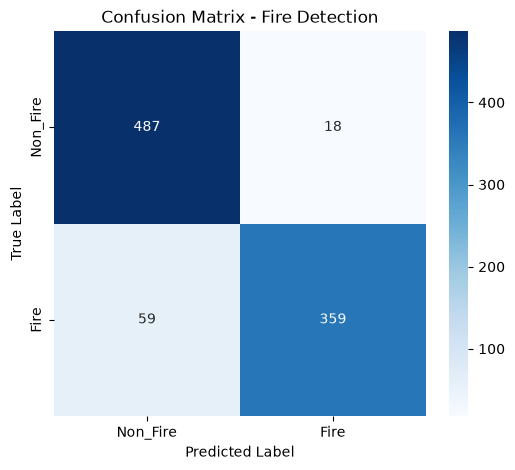


Classification Report:
              precision    recall  f1-score   support

    Non_Fire       0.89      0.96      0.93       505
        Fire       0.95      0.86      0.90       418

    accuracy                           0.92       923
   macro avg       0.92      0.91      0.91       923
weighted avg       0.92      0.92      0.92       923



In [42]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Test dataset se true labels aur predictions collect karein
y_true = []
y_pred_probs = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred_probs.extend(preds.flatten())
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)

# 2. Threshold 0.5 lagakar binary classes (0 ya 1) mein convert karein
y_pred = (y_pred_probs > 0.5).astype(int)

# 3. Confusion Matrix print aur plot karein
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Non_Fire', 'Fire'], 
            yticklabels=['Non_Fire', 'Fire'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Fire Detection')
plt.show()

# 4. Classification Report (Precision, Recall, F1-Score)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Non_Fire', 'Fire']))

In [43]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# 1. MobileNetV2 Base Model load karein (ImageNet weights ke sath)
base_model = MobileNetV2(input_shape=(224, 224, 3),
                         include_top=False,  # Last classification layer hataane ke liye
                         weights='imagenet')

# Pre-trained weights ko freeze karein taaki purane features change na hon
base_model.trainable = False

# 2. Apni custom layers add karein
mobilenet_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')  # Binary classification ke liye
])

# 3. Model Compile karein
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')]
)

mobilenet_model.summary()

# 4. Model Train karein (Wahi purana train_ds aur test_ds use hoga)
EPOCHS = 10
history_mobile = mobilenet_model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=test_ds
)

print("MobileNetV2 Training Complete! 🚀")

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10


c:\Users\bhara\OneDrive\Desktop\fire vs no fire\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


117/117 ━━━━━━━━━━━━━━━━━━━━ 58s 445ms/step - accuracy: 0.8777 - loss: 0.3075 - precision: 0.8672 - recall: 0.8667 - val_accuracy: 0.9577 - val_loss: 0.1587 - val_precision: 0.9679 - val_recall: 0.9378
Epoch 2/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 48s 413ms/step - accuracy: 0.9510 - loss: 0.1465 - precision: 0.9470 - recall: 0.9464 - val_accuracy: 0.9632 - val_loss: 0.1207 - val_precision: 0.9615 - val_recall: 0.9569
Epoch 3/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 48s 408ms/step - accuracy: 0.9655 - loss: 0.1111 - precision: 0.9633 - recall: 0.9616 - val_accuracy: 0.9697 - val_loss: 0.1073 - val_precision: 0.9779 - val_recall: 0.9545
Epoch 4/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 49s 416ms/step - accuracy: 0.9716 - loss: 0.0936 - precision: 0.9702 - recall: 0.9680 - val_accuracy: 0.9686 - val_loss: 0.1005 - val_precision: 0.9732 - val_recall: 0.9569
Epoch 5/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 47s 405ms/step - accuracy: 0.9711 - loss: 0.0891 - precision: 0.9686 - recall: 0.9686 - val_accuracy: 0.9675 - val_loss

MobileNetV2 Confusion Matrix:
 [[496   9]
 [ 18 400]]


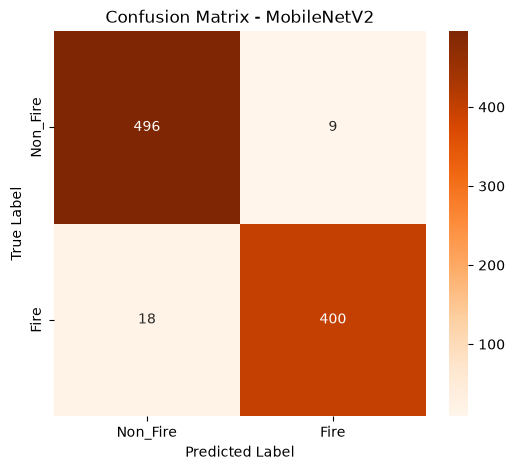


MobileNetV2 Classification Report:
              precision    recall  f1-score   support

    Non_Fire       0.96      0.98      0.97       505
        Fire       0.98      0.96      0.97       418

    accuracy                           0.97       923
   macro avg       0.97      0.97      0.97       923
weighted avg       0.97      0.97      0.97       923



In [47]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Test dataset se true labels aur predictions collect karein
y_true_mobile = []
y_pred_probs_mobile = []

for images, labels in test_ds:
    preds = mobilenet_model.predict(images, verbose=0)
    y_pred_probs_mobile.extend(preds.flatten())
    y_true_mobile.extend(labels.numpy())

y_true_mobile = np.array(y_true_mobile)
y_pred_probs_mobile = np.array(y_pred_probs_mobile)

# 2. Threshold 0.5 lagakar binary classes (0 ya 1) mein convert karein
y_pred_mobile = (y_pred_probs_mobile > 0.5).astype(int)

# 3. Confusion Matrix print aur plot karein
cm_mobile = confusion_matrix(y_true_mobile, y_pred_mobile)
print("MobileNetV2 Confusion Matrix:\n", cm_mobile)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_mobile, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=['Non_Fire', 'Fire'], 
            yticklabels=['Non_Fire', 'Fire'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - MobileNetV2')
plt.show()

# 4. Classification Report
print("\nMobileNetV2 Classification Report:")
print(classification_report(y_true_mobile, y_pred_mobile, target_names=['Non_Fire', 'Fire']))

In [48]:
mobilenet_model.save("mobilenet_fire_model.h5")
print("MobileNetV2 model successfully saved! 💾")

MobileNetV2 model successfully saved! 💾
